# Proposed CatBoost learning curves

The plotted curves use nested, stratified 25%, 50%, and 100% subsets of each shared training split. Three subset seeds are used with the CatBoost training seed fixed at 67 and one shared validation set per dataset. At 100%, the training rows and their order are identical for all subset seeds. These validation sets have been used for development. A and the group have yet to accept these proposed subset indices. Error bars describe variation over subset seeds and do not represent independent test uncertainty. This figure is for development; check Type-1 font embedding and final report formatting before submission.

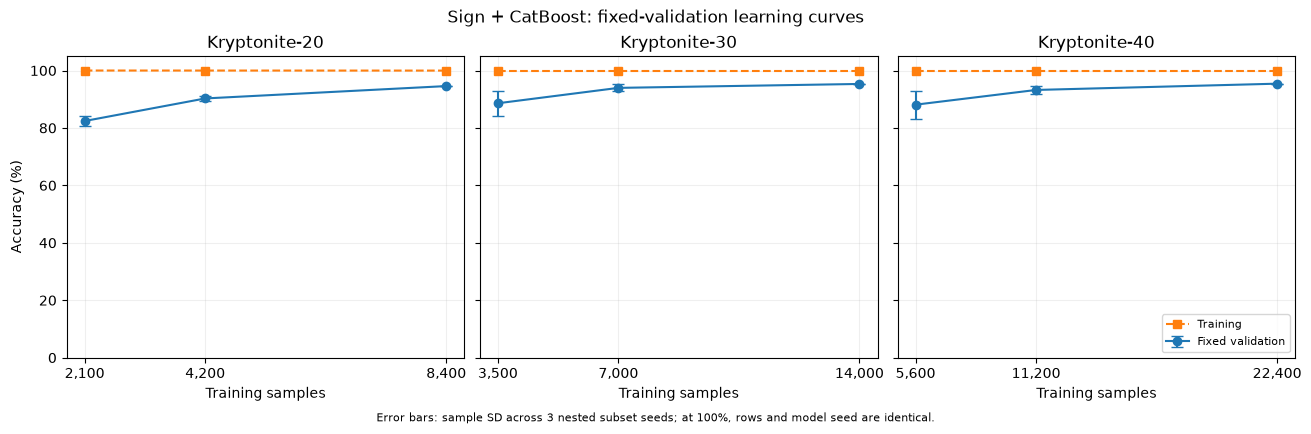

Error bars: sample SD over three subset seeds; 100% subset is identical.


In [1]:
import csv, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

root = Path.cwd().resolve()
if root.name != "B_Traditional_ML":
    root = root / "B_Traditional_ML"
results = root / "results" / "learning_curve"
progress = json.loads((results / "progress.json").read_text(encoding="utf-8"))
assert progress["state"] == "complete" and progress["completed"] == 27
with (results / "summary.csv").open(encoding="utf-8", newline="") as f:
    rows = list(csv.DictReader(f))
fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True, sharey=True)
for ax, dataset in zip(axes, ("20", "30", "40")):
    rr = sorted((r for r in rows if r["dataset"] == dataset), key=lambda r: int(r["fraction"]))
    assert len(rr) == 3 and all(int(r["completed_seeds"]) == 3 for r in rr)
    x = np.array([int(r["n_train"]) for r in rr])
    val = 100 * np.array([float(r["mean_accuracy"]) for r in rr])
    err = 100 * np.array([float(r["std_accuracy"]) for r in rr])
    train = 100 * np.array([float(r["mean_train_accuracy"]) for r in rr])
    ax.errorbar(x, val, yerr=err, marker="o", capsize=4, label="Fixed validation")
    ax.plot(x, train, marker="s", linestyle="--", label="Training")
    ax.set_xticks(x, [f"{n:,}" for n in x])
    ax.set_xlabel("Training samples")
    ax.set_title(f"Kryptonite-{dataset}")
    ax.set_ylim(0, 105)
    ax.grid(alpha=.2)
axes[0].set_ylabel("Accuracy (%)")
axes[-1].legend(loc="lower right", fontsize=8)
fig.suptitle("Sign + CatBoost: fixed-validation learning curves", fontsize=12)
fig.text(0.5, -0.04, "Error bars: sample SD across 3 nested subset seeds; at 100%, rows and model seed are identical.", ha="center", fontsize=8)
folder = results / "figures"
folder.mkdir(parents=True, exist_ok=True)
fig.savefig(folder / "learning_curve.png", dpi=180, bbox_inches="tight")
fig.savefig(folder / "learning_curve.pdf", bbox_inches="tight")
plt.show()
print("Error bars: sample SD over three subset seeds; 100% subset is identical.")